# 실물 재평가 (새 라벨)

experiment_2 모델 4개를 재라벨한 실물 49장으로 다시 평가해요.
- 데이터셋: 레포 `yolo/datasets/real_eval4` (5클래스 라벨에서 바코드 줄만 뺀 것, 모델이 4클래스라서)
- 결과: archive `eval/experiment_2_real_new/`

## 1. 경로 정하기
`True True`가 나오면 다음으로

In [3]:
from pathlib import Path
REPO = Path.home() / "바탕화면/git/Project2_Turtle_Ninja"
ARCH = Path.home() / "바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive"
EXP  = REPO / "yolo/train/results/experiment_2_linear_20261023_164149"
DATA = REPO / "yolo/datasets/real_eval4/data.yaml"
OUT  = ARCH / "eval/experiment_2_real_new"
print(DATA.exists(), (EXP / "b8/weights/best_map50.pt").exists())

True True


## 2. 모델 4개 평가 → 표
몇 분 걸려요

In [4]:
from ultralytics import YOLO
import pandas as pd

rows = []
for b in [8, 12, 16, 20]:
    m = YOLO(EXP / f"b{b}/weights/best_map50.pt")
    r = m.val(data=str(DATA), imgsz=1280, batch=8, project=str(OUT), name=f"b{b}", exist_ok=True, verbose=False)
    row = {"batch": b, "all mAP50": round(r.box.map50, 3), "P": round(r.box.mp, 3), "R": round(r.box.mr, 3)}
    for i, c in enumerate(r.box.ap_class_index):
        row[f"{m.names[int(c)]} mAP50"] = round(r.box.class_result(i)[2], 3)
    rows.append(row)

df = pd.DataFrame(rows)
df

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5238.3±1589.8 MB/s, size: 332.0 KB)
val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_eval4/labels... 49 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 1.4Kit/s 0.0s
val: New cache created: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_eval4/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.0it/s 1.4s0.1ss
                   all         49         73      0.604      0.523      0.604      0.321
Speed: 4.9ms preprocess, 7.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/eval/experiment_2_real_new/b8
Ultralytics 8.4.183 

,batch,all mAP50,P,R,qr mAP50,puck_cyl mAP50,puck_box mAP50,signal_tower mAP50
0,8,0.604,0.604,0.523,0.0,0.817,0.847,0.753
1,12,0.567,0.586,0.505,0.0,0.871,0.888,0.509
2,16,0.604,0.604,0.523,0.0,0.817,0.847,0.753
3,20,0.615,0.685,0.489,0.0,0.804,0.824,0.830


## 3. 그림으로 확인
표에서 `all mAP50`이 가장 높은 batch 번호를 `b =`에 넣고 실행

val_batch0_labels.jpg


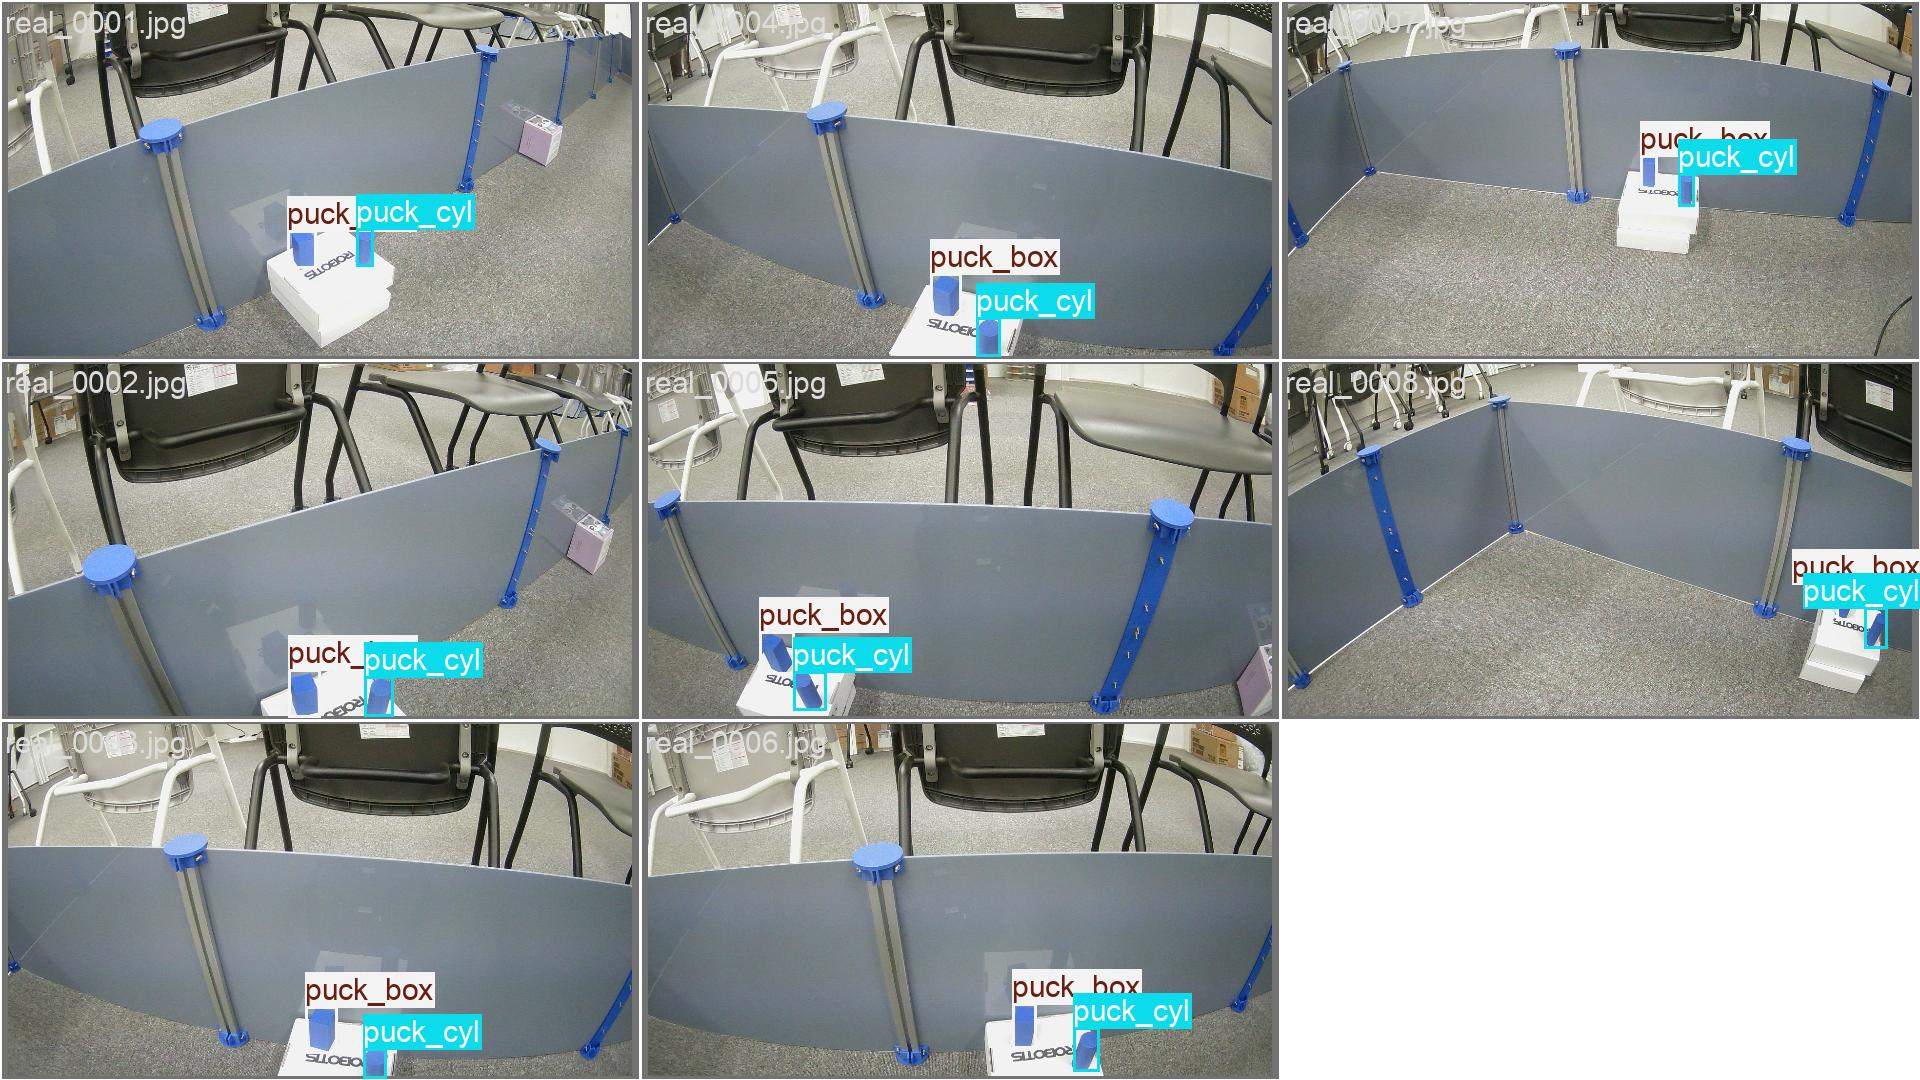

val_batch0_pred.jpg


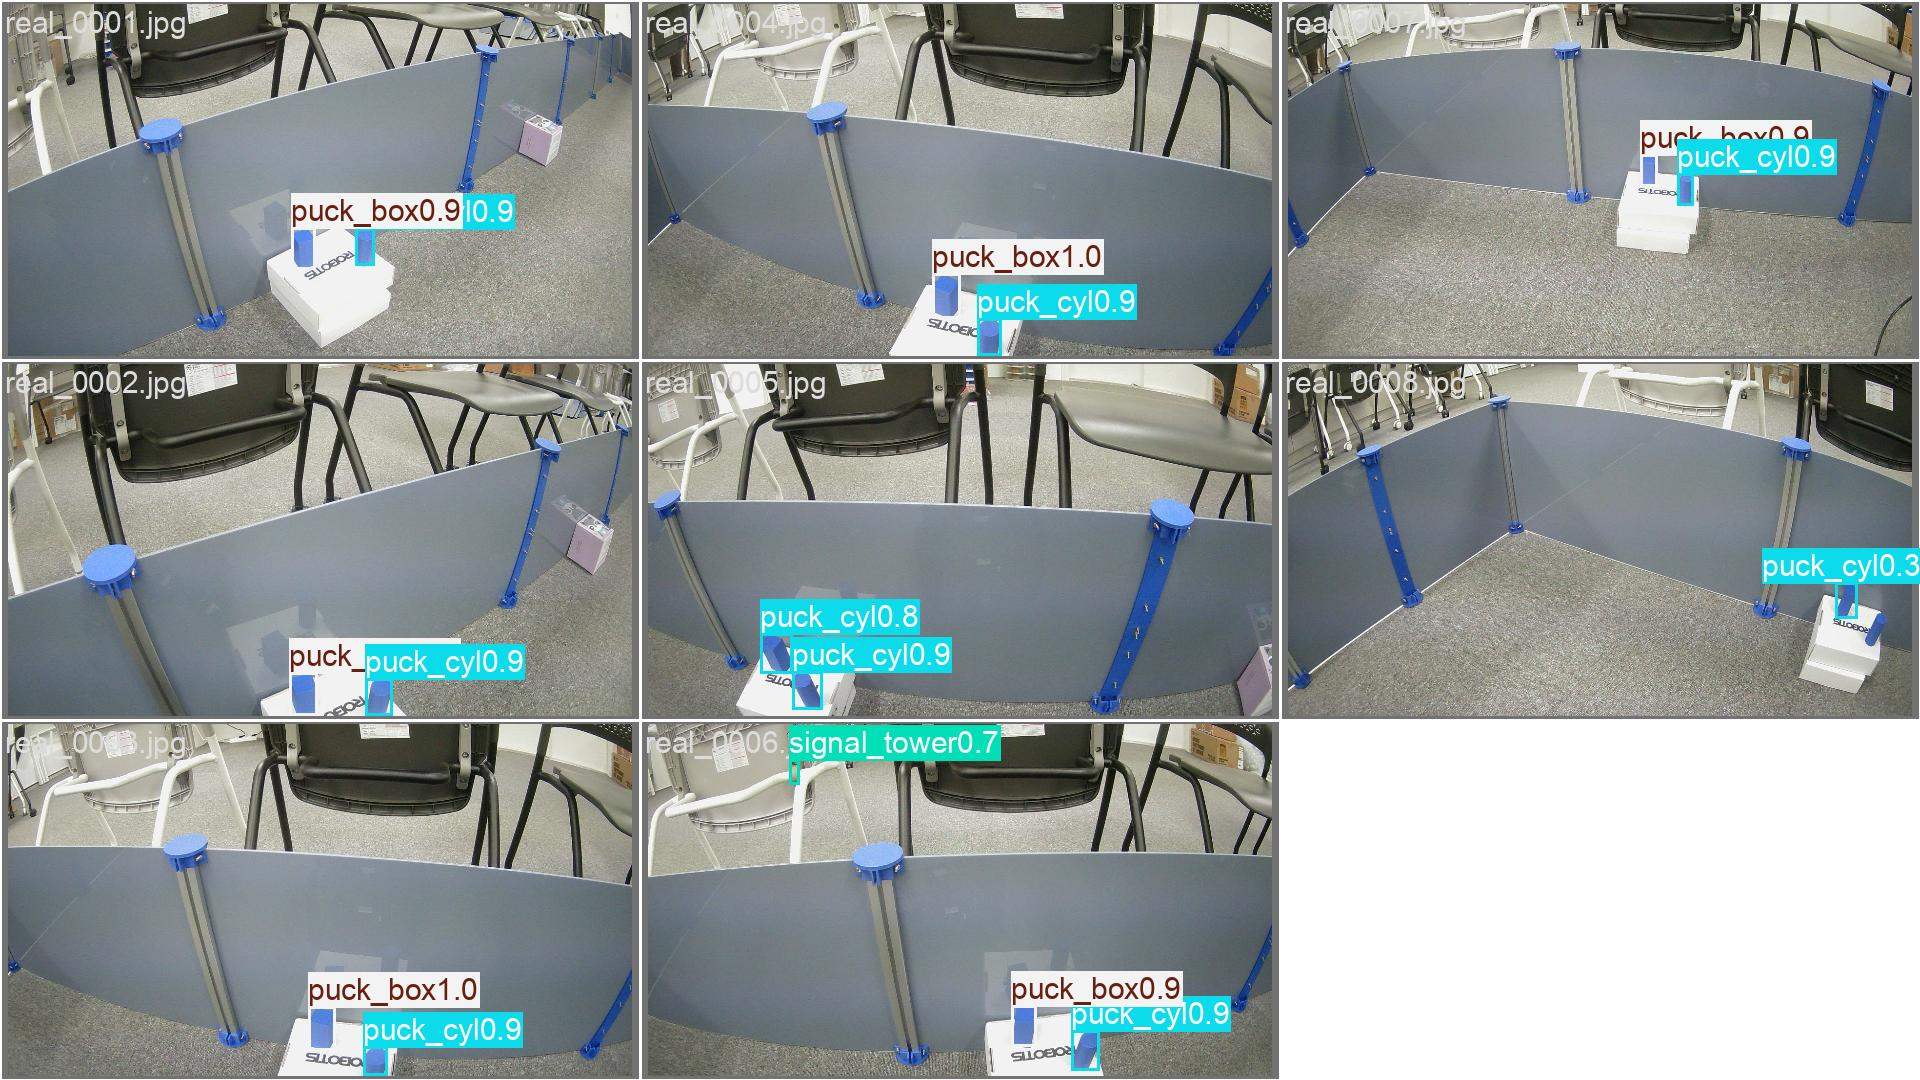

confusion_matrix.png


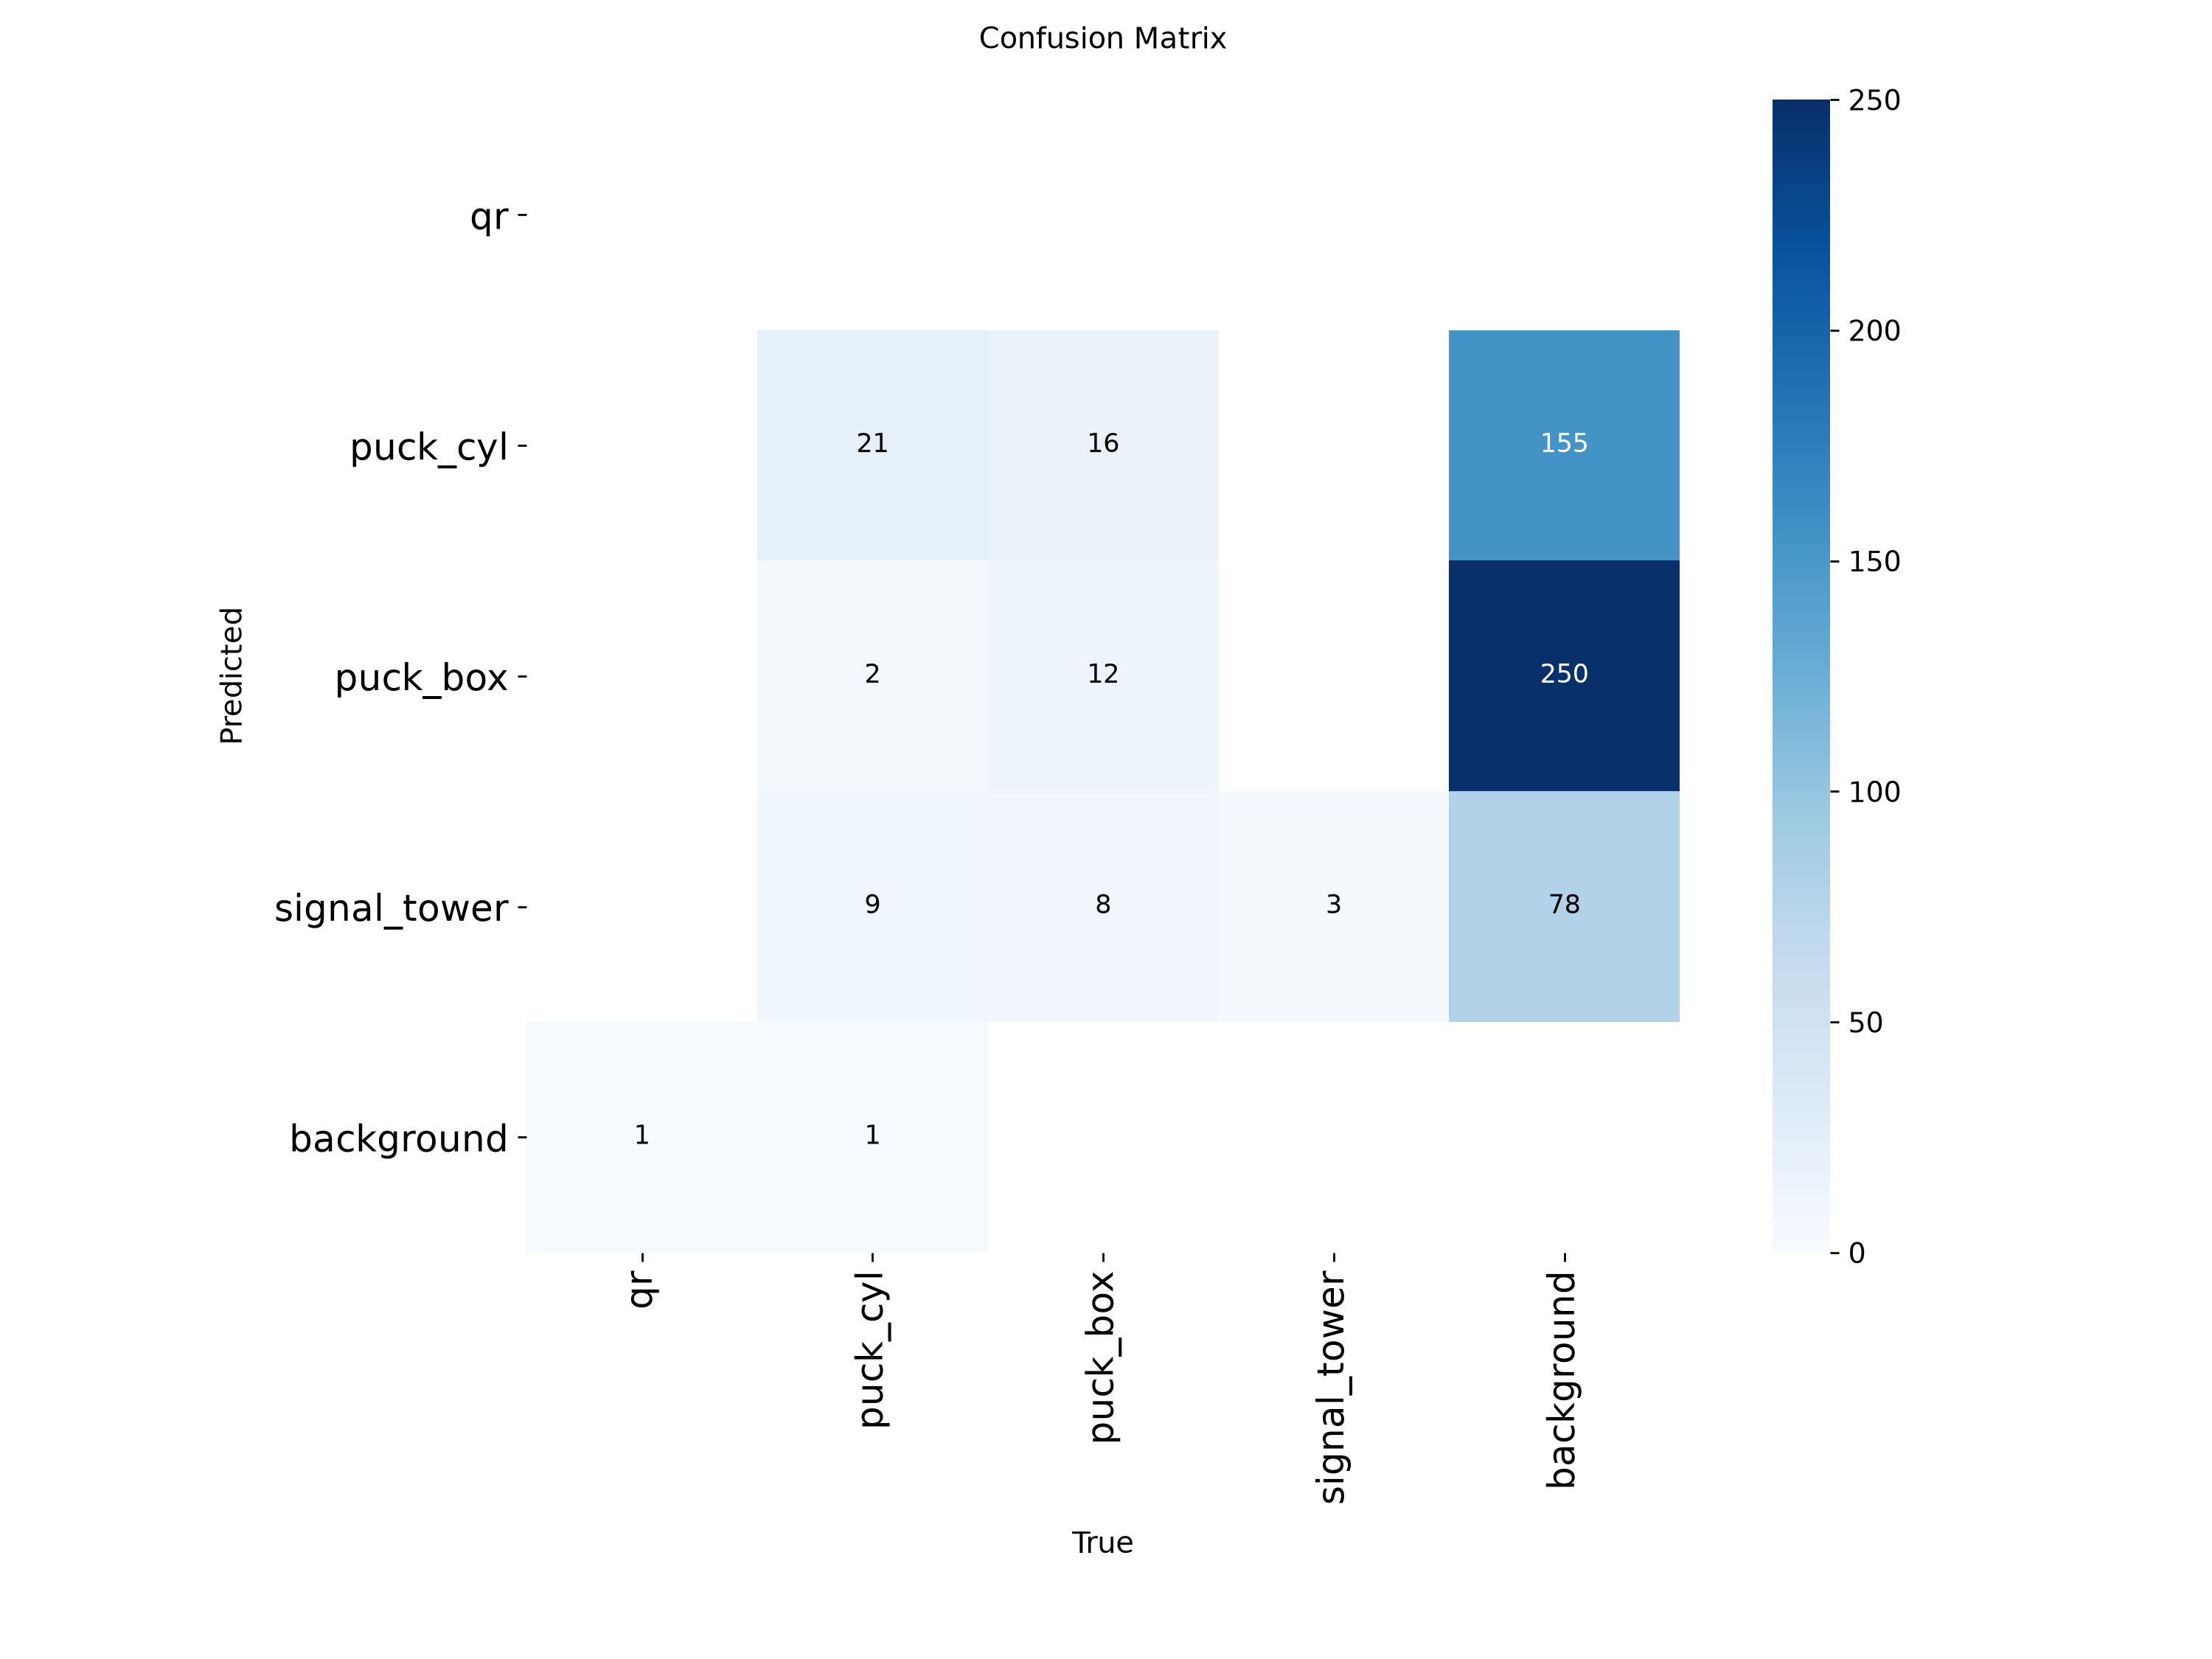

In [5]:
from IPython.display import Image, display
b = 12
for f in ["val_batch0_labels.jpg", "val_batch0_pred.jpg", "confusion_matrix.png"]:
    print(f); display(Image(filename=str(OUT / f"b{b}" / f), width=900))